In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

# SelectKBest ku badhila PCA boss - same style!
def pca(indep_X, n):
    pca = PCA(n_components=n)
    pca_features = pca.fit_transform(indep_X)
    return pca_features

def split_scalar(indep_X, dep_Y):
    X_train, X_test, y_train, y_test = train_test_split(indep_X, dep_Y, test_size=0.2, random_state=0)
    sc = StandardScaler()
    X_train = sc.fit_transform(X_train)
    X_test = sc.transform(X_test)
    return X_train, X_test, y_train, y_test

def cm_prediction(classifier, X_test, y_test):
    y_pred = classifier.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    Accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred)
    return classifier, Accuracy, report, X_test, y_test, cm

# Thani thani model function - unga SelectKBest maadhiri boss!
def logistic(X_train, y_train, X_test, y_test):
    from sklearn.linear_model import LogisticRegression
    classifier = LogisticRegression(random_state=0)
    classifier.fit(X_train, y_train)
    classifier, Accuracy, report, X_test, y_test, cm = cm_prediction(classifier, X_test, y_test)
    return classifier, Accuracy, report, X_test, y_test, cm

def svm_linear(X_train, y_train, X_test, y_test):
    from sklearn.svm import SVC
    classifier = SVC(kernel='linear', random_state=0)
    classifier.fit(X_train, y_train)
    classifier, Accuracy, report, X_test, y_test, cm = cm_prediction(classifier, X_test, y_test)
    return classifier, Accuracy, report, X_test, y_test, cm

def svm_NL(X_train, y_train, X_test, y_test):
    from sklearn.svm import SVC
    classifier = SVC(kernel='rbf', random_state=0)
    classifier.fit(X_train, y_train)
    classifier, Accuracy, report, X_test, y_test, cm = cm_prediction(classifier, X_test, y_test)
    return classifier, Accuracy, report, X_test, y_test, cm

def knn(X_train, y_train, X_test, y_test):
    from sklearn.neighbors import KNeighborsClassifier
    classifier = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2)
    classifier.fit(X_train, y_train)
    classifier, Accuracy, report, X_test, y_test, cm = cm_prediction(classifier, X_test, y_test)
    return classifier, Accuracy, report, X_test, y_test, cm

def Navie(X_train, y_train, X_test, y_test):
    from sklearn.naive_bayes import GaussianNB
    classifier = GaussianNB()
    classifier.fit(X_train, y_train)
    classifier, Accuracy, report, X_test, y_test, cm = cm_prediction(classifier, X_test, y_test)
    return classifier, Accuracy, report, X_test, y_test, cm

def Decision(X_train, y_train, X_test, y_test):
    from sklearn.tree import DecisionTreeClassifier
    classifier = DecisionTreeClassifier(criterion='entropy', random_state=0)
    classifier.fit(X_train, y_train)
    classifier, Accuracy, report, X_test, y_test, cm = cm_prediction(classifier, X_test, y_test)
    return classifier, Accuracy, report, X_test, y_test, cm

def random(X_train, y_train, X_test, y_test):
    from sklearn.ensemble import RandomForestClassifier
    classifier = RandomForestClassifier(n_estimators=10, criterion='entropy', random_state=0)
    classifier.fit(X_train, y_train)
    classifier, Accuracy, report, X_test, y_test, cm = cm_prediction(classifier, X_test, y_test)
    return classifier, Accuracy, report, X_test, y_test, cm

In [11]:
dataset = pd.read_csv('Wine.csv')
indep_X = dataset.iloc[:, 0:13].values
dep_Y = dataset.iloc[:, 13].values

acclog = []
accsvml = []
accsvmnl = []
accknn = []
accnavie = []
accdec = []
accrand = []

for n in [2,3,6]:
    X_pca = pca(indep_X, n)
    X_train, X_test, y_train, y_test = split_scalar(X_pca, dep_Y)
    
    _, acc, _, _, _, _ = logistic(X_train, y_train, X_test, y_test)
    acclog.append(acc)
    
    _, acc, _, _, _, _ = svm_linear(X_train, y_train, X_test, y_test)
    accsvml.append(acc)
    
    _, acc, _, _, _, _ = svm_NL(X_train, y_train, X_test, y_test)
    accsvmnl.append(acc)
    
    _, acc, _, _, _, _ = knn(X_train, y_train, X_test, y_test)
    accknn.append(acc)
    
    _, acc, _, _, _, _ = Navie(X_train, y_train, X_test, y_test)
    accnavie.append(acc)
    
    _, acc, _, _, _, _ = Decision(X_train, y_train, X_test, y_test)
    accdec.append(acc)
    
    _, acc, _, _, _, _ = random(X_train, y_train, X_test, y_test)
    accrand.append(acc)

table = pd.DataFrame({
    'PCA n=2': [acclog[0], accsvml[0], accsvmnl[0], accknn[0], accnavie[0], accdec[0], accrand[0]],
    'PCA n=3': [acclog[1], accsvml[1], accsvmnl[1], accknn[1], accnavie[1], accdec[1], accrand[1]],
    'PCA n=6': [acclog[2], accsvml[2], accsvmnl[2], accknn[2], accnavie[2], accdec[2], accrand[2]]
}, index=['Logistic','SVMl','SVMnl','KNN','Navie','Decision','Random'])

print(table.T)

         Logistic      SVMl     SVMnl       KNN     Navie  Decision    Random
PCA n=2  0.777778  0.777778  0.805556  0.722222  0.777778  0.722222  0.777778
PCA n=3  0.888889  0.888889  0.888889  0.805556  0.861111  0.861111  0.888889
PCA n=6  0.944444  0.944444  1.000000  0.944444  0.972222  0.944444  0.916667


In [12]:
# Fitting Logistic Regression to the Training set
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(random_state = 0)
classifier.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,0
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


C:\Users\DELL\AppData\Local\Temp\ipykernel_12552\2665120901.py:24: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


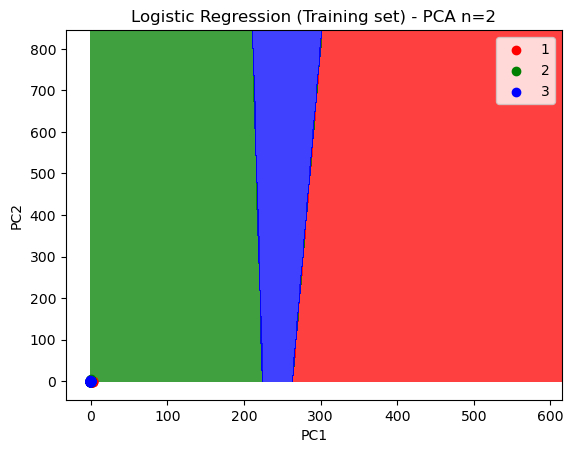

C:\Users\DELL\AppData\Local\Temp\ipykernel_12552\2665120901.py:39: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


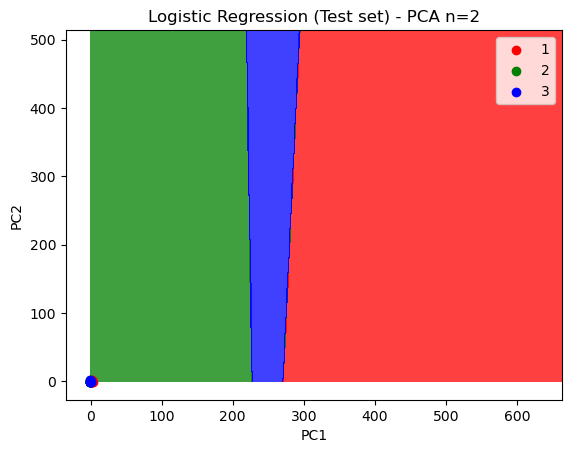

In [15]:
# CELL 3 - Visualization - Final Working Code - Itha mattum paste pannunga!
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# 1. Dataset fresh ah load pannurom boss - ithu mukkiyam!
dataset = pd.read_csv('Wine.csv')
indep_X = dataset.iloc[:, 0:13].values
dep_Y = dataset.iloc[:, 13].values

# 2. PCA n=2 ku pudhusa train pannurom - pazhaya 6 feature model vendaam!
X_pca = pca(indep_X, 2)
X_train, X_test, y_train, y_test = split_scalar(X_pca, dep_Y)
classifier, Accuracy, report, X_test, y_test, cm = logistic(X_train, y_train, X_test, y_test)

# 3. Training set Visualization
X_set, y_set = X_train, y_train
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1, stop = X_set[:, 0].max() + 1, step = 0.01),
                     np.arange(start = X_set[:, 1].min() - 1, stop = X_set[:, 1].max() + 1, step = 0.01))
plt.contourf(classifier.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('red', 'green', 'blue')))
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                c = ListedColormap(('red', 'green', 'blue'))(i), label = j)
plt.title('Logistic Regression (Training set) - PCA n=2')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.show()

# 4. Test set Visualization
X_set, y_set = X_test, y_test
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1, stop = X_set[:, 0].max() + 1, step = 0.01),
                     np.arange(start = X_set[:, 1].min() - 1, stop = X_set[:, 1].max() + 1, step = 0.01))
plt.contourf(classifier.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('red', 'green', 'blue')))
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                c = ListedColormap(('red', 'green', 'blue'))(i), label = j)
plt.title('Logistic Regression (Test set) - PCA n=2')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.show()